# 📘 Notebook 11: Vision Transformer, an Image Is Worth 16 × 16 Words

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Paper: Dosovitskiy et al. (2020)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** A small Vision Transformer (4 layers, 64 dimensions) and a small convolutional network of similar size train for 2 epochs on Fashion-MNIST, first on all 60,000 images and then on only 3,000: about **17 minutes** in total on a laptop processor, a few minutes on a Colab GPU. The paper's models had up to 632 million weights and were **pretrained on 300 million images** (Google's private JFT-300M) before being fine-tuned; its central finding is that Transformers beat convolutional networks only with that much data. Our experiment reproduces the **other half** of that finding, what happens with little data. Section 5 uses the official pretrained ViT-B/16 weights from torchvision (about 330 MB) for real photographs.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Turn an image into a **sequence of patches** and embed them like words
- Explain the **class token** and **learned position embeddings** of the ViT
- Build a Vision Transformer from the Transformer blocks of Notebook 07
- Compare a ViT with a CNN of similar size on **plenty** and on **little** data
- Explain **inductive bias**: what convolutions assume about images, and why it helps when data is scarce
- Use a pretrained ViT and see what its attention looks at

> **Prerequisites:** [Notebook 07: The Transformer](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/07_transformer.ipynb) and [Notebook 02: LeNet-5](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/02_lenet5.ipynb).
>
> 🔭 **Why this notebook matters:** for thirty years, images meant convolutions. The 2020 ViT paper showed that a standard Transformer, with almost no image-specific design, can match or beat the best CNNs, if it sees enough data. That opened the way to one architecture for text, images, audio and video, which is how today's multimodal models (models that read both text and images) are built.

## 1. The paper

> 📄 A. Dosovitskiy et al., [*An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*](https://arxiv.org/abs/2010.11929), ICLR 2021 (arXiv 2020).

### Intuition first
A Transformer reads a sequence of tokens. An image is a grid of pixels. The ViT's trick is almost embarrassingly simple:
1. cut the image into **patches** (16 × 16 pixels in the paper; 7 × 7 here, for 28 × 28 images);
2. flatten each patch and map it with one linear layer to a vector: a **patch embedding**, the image's version of a word embedding;
3. add a **learned position embedding** to each patch, so the model knows where it came from;
4. put an extra learnable **class token** at the front of the sequence;
5. run standard Transformer blocks; the class token's final vector, passed through a linear layer, gives the answer.

There is no convolution, no pooling, no built-in notion that nearby pixels belong together. A CNN **assumes** locality and that the same pattern can appear anywhere (its **inductive bias**). A ViT must **learn** these facts from data, which is why it needs so much of it.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gzip
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)
def images(name):
    return (torch.tensor(read_idx(name, 16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255 - 0.286) / 0.353
X_train, X_test = images("train-images-idx3-ubyte.gz"), images("t10k-images-idx3-ubyte.gz")
y_train = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
print("train", tuple(X_train.shape), " test", tuple(X_test.shape))

train (60000, 1, 28, 28)  test (10000, 1, 28, 28)


## 2. An image as a sequence of patches

one image becomes 16 patches of 49 pixels


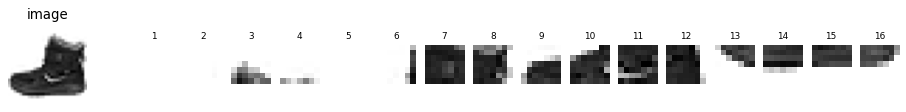

In [2]:
PATCH = 7
def to_patches(x):
    """(batch, 1, 28, 28) -> (batch, 16 patches, 49 pixels)"""
    b = x.size(0)
    return x.unfold(2, PATCH, PATCH).unfold(3, PATCH, PATCH).reshape(b, -1, PATCH * PATCH)

p = to_patches(X_train[:1])
print("one image becomes", p.shape[1], "patches of", p.shape[2], "pixels")
fig, axes = plt.subplots(1, 17, figsize=(15, 1.3), gridspec_kw={"width_ratios": [4] + [1] * 16})
axes[0].imshow(X_train[0, 0], cmap="gray_r"); axes[0].set_title("image"); axes[0].axis("off")
for i in range(16):
    axes[i + 1].imshow(p[0, i].reshape(PATCH, PATCH), cmap="gray_r", vmin=X_train.min(), vmax=X_train.max())
    axes[i + 1].set_title(str(i + 1), fontsize=8); axes[i + 1].axis("off")
plt.show()

**What we see.** A 28 × 28 image becomes a sequence of **16 patches** of 7 × 7 pixels, numbered row by row from the top left. Once flattened, each patch is just a list of 49 numbers, and the model sees nothing else: patch 1 and patch 2 are neighbours in the image, but the model is not told so. Anything it knows about where a patch sits must come from the position embeddings.

## 3. The model, and a CNN to compare with

The Transformer block is the one written by hand in Notebook 07, here taken from PyTorch (`nn.TransformerEncoderLayer`, in its pre-norm form) to keep the notebook short. The comparison CNN has two convolutional layers and a similar number of weights.

In [3]:
class ViT(nn.Module):
    def __init__(self, d=64, heads=4, layers=4, classes=10):
        super().__init__()
        self.patch_embed = nn.Linear(PATCH * PATCH, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, 17, d) * 0.02)          # learned positions: 16 patches + class token
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.1, activation="gelu", batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, classes)

    def forward(self, x):
        tokens = self.patch_embed(to_patches(x))
        tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], 1) + self.pos
        return self.head(self.norm(self.blocks(tokens))[:, 0])        # read the answer from the class token

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Flatten(), nn.Linear(64 * 7 * 7, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 10))
    def forward(self, x):
        return self.net(x)

count = lambda m: sum(p.numel() for p in m.parameters())
print("ViT weights:", f"{count(ViT()):,}", "   CNN weights:", f"{count(SmallCNN()):,}")

ViT weights: 205,066    CNN weights: 220,234


**What we see.** The two models have about the same number of weights (**205,066** for the ViT, **220,234** for the CNN), so any difference comes from the architecture, not from size.

## 4. Plenty of data against little data

We train both models for 2 epochs on all 60,000 training images, and again on only the first 3,000 (with the same number of updates, so that the small-data models see each image 40 times), and test on the same 10,000 images.

In [4]:
def train(model_class, n_images, steps, batch=128, seed=0):
    torch.manual_seed(seed)
    model = model_class()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=steps)
    start = time.time()
    for _ in range(steps):
        idx = torch.randint(0, n_images, (batch,))
        loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model.eval()
    with torch.no_grad():
        acc = sum((model(X_test[i:i + 1000]).argmax(1) == y_test[i:i + 1000]).sum().item() for i in range(0, 10000, 1000)) / 10000
    return model, acc, time.time() - start

STEPS = 2 * 60000 // 128
rows, models = {}, {}
for n in [60000, 3000]:
    for name, cls in [("ViT", ViT), ("CNN", SmallCNN)]:
        model, acc, seconds = train(cls, n, STEPS)
        models[(name, n)] = model
        rows.setdefault(f"{n:,} training images", {})[name] = acc
        print(f"{name} on {n:>6,} images: test accuracy {acc:.3f}   ({seconds:.0f} s)")
pd.DataFrame(rows).T.round(3)

ViT on 60,000 images: test accuracy 0.844   (353 s)


CNN on 60,000 images: test accuracy 0.884   (139 s)


ViT on  3,000 images: test accuracy 0.800   (332 s)


CNN on  3,000 images: test accuracy 0.863   (164 s)


,ViT,CNN
"60,000 training images",0.844,0.884
"3,000 training images",0.800,0.863


**What we see.** A clear and honest result:
- With **60,000** images, the CNN reaches **88.4%** and the ViT **84.4%**: a 4-point lead for the CNN.
- With only **3,000** images, the gap **grows** to more than 6 points: **86.3%** for the CNN against **80.0%** for the ViT.

At this scale the CNN wins everywhere, and its lead increases as data shrinks. This is exactly the paper's finding seen from the small end: on ImageNet alone (1.3 million images), the ViT was also *worse* than comparable ResNets; it only overtook them after pretraining on 300 million images. The convolution's built-in assumptions (look locally, reuse the same detector everywhere) are worth a great deal of data. The ViT also trains more slowly per step on a processor (about 350 s against 140 s here).

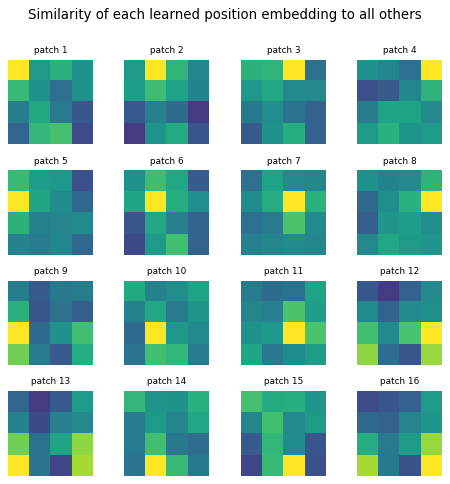

In [5]:
pos = models[("ViT", 60000)].pos[0, 1:].detach()
sim = F.cosine_similarity(pos[:, None], pos[None], dim=-1)
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(sim[i].reshape(4, 4), cmap="viridis", vmin=-1, vmax=1)
    ax.set_title(f"patch {i + 1}", fontsize=8); ax.axis("off")
plt.suptitle("Similarity of each learned position embedding to all others", y=1.0)
plt.tight_layout()
plt.show()

**What we see.** Each small panel shows how similar one patch's learned position embedding is to those of all 16 positions, arranged as the 4 × 4 grid. The bright square marks the patch itself. Around it, a **weak** structure has begun to appear: several patches are more similar to their neighbours in the same row or column (patches 9 and 13, for example, resemble the patches below and above them). After only two epochs on small images the pattern is faint; in the paper, with far more training, the embeddings clearly rediscover rows and columns. The model is **learning** the 2D layout that a CNN has built in.

## 5. A pretrained ViT on real photographs

The `vit_b_16` model in torchvision was pretrained on ImageNet-1k with heavy augmentation and regularisation (the recipe of later papers that made ViTs work without a huge private dataset). We use it on the same photos as Notebook 03.

In [6]:
from torchvision.models import vit_b_16, ViT_B_16_Weights
from skimage import data as skdata

weights = ViT_B_16_Weights.IMAGENET1K_V1
vit = vit_b_16(weights=weights, progress=False).eval()
prepare = weights.transforms()
categories = weights.meta["categories"]
photos = {"cat": skdata.chelsea(), "coffee": skdata.coffee(), "rocket": skdata.rocket()}
for name, image in photos.items():
    with torch.no_grad():
        p = vit(prepare(torch.tensor(image).permute(2, 0, 1))[None]).softmax(1)[0]
    v, i = p.topk(3)
    print(f"{name:7s}", [(categories[k], round(val.item(), 3)) for val, k in zip(v, i)])
print("\nweights:", f"{count(vit):,}", "  ImageNet top-1 accuracy:", weights.meta["_metrics"]["ImageNet-1K"]["acc@1"], "%")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\ioann/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


cat     [('Egyptian cat', 0.661), ('tiger cat', 0.099), ('tabby', 0.088)]


coffee  [('espresso', 0.903), ('cup', 0.011), ('coffee mug', 0.002)]


rocket  [('drilling platform', 0.587), ('crane', 0.095), ('beacon', 0.054)]

weights: 86,567,656   ImageNet top-1 accuracy: 81.072 %


**What we see.** The pretrained ViT-B/16 has **86.6 million** weights and reaches **81.1%** top-1 accuracy on ImageNet, better than ResNet-50's 76.1% (Notebook 04) but with more than three times the weights. It recognises the cat (Egyptian cat, **66%**) and the espresso (**90%**), and, like AlexNet, misreads the rocket, here as a drilling platform. Strong architectures still fail on images unlike their training data. (The download line in the output appears once, when the weights are first fetched.)

## ⚠️ Common pitfalls

- **Training a ViT from scratch on a small dataset.** Without convolutions' built-in assumptions, it needs far more data or strong augmentation; with little data, a CNN or a pretrained ViT is the better choice.
- **Forgetting position embeddings.** Without them the patches are an unordered set (Notebook 07), and the model cannot tell a shoe from its mirror image.
- **Patch size and image size.** The image must divide into whole patches; smaller patches mean longer sequences and quadratically more attention computation.
- **Feeding a pretrained ViT images of the wrong size.** Its position embeddings were learned for a fixed grid of patches (14 × 14 for 224 × 224 images); use the weights' transforms.
- **Comparing architectures with one setting.** Which model wins depends on data size, training length and augmentation, as Section 4 shows.

## ✏️ Exercises

### Exercise 1 (Shuffle the patches)
Take the ViT trained on 60,000 images and test it on images whose 16 patches have been **shuffled** into a random order (the same shuffle for all images). Do the same for the CNN, shuffling the 7 × 7 blocks of the image. Which model is hurt more, and why?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
perm = torch.randperm(16, generator=torch.Generator().manual_seed(0))
def shuffle_blocks(x):
    blocks = x.unfold(2, 7, 7).unfold(3, 7, 7).reshape(len(x), 1, 16, 7, 7)[:, :, perm]
    return blocks.reshape(len(x), 1, 4, 4, 7, 7).permute(0, 1, 2, 4, 3, 5).reshape(len(x), 1, 28, 28)

for name in ["ViT", "CNN"]:
    m = models[(name, 60000)]
    with torch.no_grad():
        acc = (m(shuffle_blocks(X_test[:2000])).argmax(1) == y_test[:2000]).float().mean().item()
    print(f"{name}: accuracy on shuffled images {acc:.3f}")
```

*Both models collapse, because both learned where things usually are. Shuffling patches does not change what each patch contains, only where it is, so the drop shows how much each model relies on the arrangement of the parts. The exact numbers differ between runs; the lesson is that neither architecture is magically invariant to rearrangement.*
</details>

### Exercise 2 (Smaller patches)
Change `PATCH` to 4 (49 patches of 16 pixels; adjust the size of `self.pos` to 50) and train the ViT on 60,000 images for 300 steps, comparing it with the 7 × 7 ViT trained for the same 300 steps. Is it more accurate, and how much slower is it?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
PATCH = 4
class ViT4(ViT):
    def __init__(self):
        super().__init__()
        self.patch_embed = nn.Linear(16, 64)
        self.pos = nn.Parameter(torch.randn(1, 50, 64) * 0.02)

model4, acc4, sec4 = train(ViT4, 60000, 300)
PATCH = 7
model7, acc7, sec7 = train(ViT, 60000, 300)
print(f"patch 4: accuracy {acc4:.3f} in {sec4:.0f} s   patch 7: accuracy {acc7:.3f} in {sec7:.0f} s")
```

*Smaller patches give the model finer detail but three times as many tokens, and attention cost grows with the square of the number of tokens, so each step is much slower. This trade-off between resolution and cost is why ViTs use large patches on large images.*
</details>

### Exercise 3 (Attention from the class token)
For one test image, take the ViT trained on 60,000 images and compute which patches the **class token** attends to in the last layer. Hint: run the blocks manually and call the attention module of the last layer with `need_weights=True`.

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
vit_small = models[("ViT", 60000)]
x = X_test[:1]
with torch.no_grad():
    h = torch.cat([vit_small.cls, vit_small.patch_embed(to_patches(x))], 1) + vit_small.pos
    for layer in vit_small.blocks.layers[:-1]:
        h = layer(h)
    last = vit_small.blocks.layers[-1]
    _, w = last.self_attn(last.norm1(h), last.norm1(h), last.norm1(h), need_weights=True)
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(x[0, 0], cmap="gray_r"); axes[0].axis("off")
axes[1].imshow(w[0, 0, 1:].reshape(4, 4), cmap="viridis"); axes[1].axis("off"); axes[1].set_title("class token attention")
plt.show()
```

*The class token typically attends most to the patches that contain the object's distinctive parts (the toe of a shoe, the neck of a shirt) and little to the empty corners, a direct view of what the model uses to decide.*
</details>

## 🔑 Key takeaways

- A **Vision Transformer** cuts an image into patches, embeds them like words, adds **position embeddings** and a **class token**, and applies a standard Transformer.
- It has almost no built-in assumptions about images, so it must learn locality from **data**.
- With **plenty** of data it can match CNNs; with **little** data a CNN's inductive bias wins. This is the paper's central finding, seen from the small-data side.
- Learned position embeddings slowly **learn** the 2D layout that a CNN has built in.
- Pretrained ViTs are now standard image backbones, and the same design reads text, images and audio in multimodal models.

---
**Next:** *Notebook 12: Diffusion Models*, where a network learns to remove noise step by step, and generates images by starting from pure noise.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*